In [ ]:
import pandas as pd
file_path = "/content/gpt-5.1_espontaneo.tsv"
NER_results_esp = pd.read_csv(file_path, sep='\t')
NER_results_esp=NER_results_esp.rename(columns={"0": "sentence", "1": "analysis"})
file_path2 = "/content/gpt-5.1_sintetico.tsv"
NER_results_syn = pd.read_csv(file_path2, sep='\t')
NER_results_syn=NER_results_syn.rename(columns={"0": "sentence", "1": "analysis"})

In [ ]:
import ast
import json

def extract_text_and_label(analysis_str):
    texts = []
    labels = []
    if pd.isna(analysis_str) or analysis_str.strip() == '[]' or analysis_str.strip() == '[nan]':
        return [], []
    try:
        parsed_list = ast.literal_eval(analysis_str)
        if isinstance(parsed_list, list):
            for item in parsed_list:
                if isinstance(item, dict):
                    texts.append(item.get('text'))
                    labels.append(item.get('label'))
    except (ValueError, SyntaxError, json.JSONDecodeError) as e:
        # Fallback to json.loads if ast.literal_eval fails for some reason (e.g., strict JSON)
        try:
            parsed_list = json.loads(analysis_str)
            if isinstance(parsed_list, list):
                for item in parsed_list:
                    if isinstance(item, dict):
                        texts.append(item.get('text'))
                        labels.append(item.get('label'))
        except (json.JSONDecodeError, ValueError, SyntaxError) as inner_e:
            # Handle cases where parsing completely fails
            pass # Return empty lists
    return texts, labels

# Apply the function to the 'analysis' column
extracted_data = NER_results_esp['analysis'].apply(extract_text_and_label)

# Assign the results to new columns
NER_results_esp['extracted_texts'] = [x[0] for x in extracted_data]
NER_results_esp['extracted_labels'] = [x[1] for x in extracted_data]

# Display the head of the DataFrame with the new columns
#print(NER_results[['sentence', 'analysis', 'extracted_texts', 'extracted_labels']].head())

In [ ]:
NER_results_esp

,sentence,analysis,extracted_texts,extracted_labels
0,"Argentina: Esfera un foco, un foquito más, par...","[\n {\n ""text"": ""Argentina"",\n ""label"":...",[Argentina],[LOC]
1,Argentina: ¡Bienvenido! ¿Viste?,"[\n {\n ""text"": ""Argentina"",\n ""label"":...",[Argentina],[LOC]
2,Rodolfo: ¿Qué?,"[\n {\n ""text"": ""Rodolfo"",\n ""label"": ""...",[Rodolfo],[PER]
3,Argentina: El restauran. Bienvenido al restaur...,"[\n {\n ""text"": ""Argentina"",\n ""label"":...","[Argentina, Santa Argentina]","[LOC, LOC]"
4,Gladys: Buenas…,[],[],[]
...,...,...,...,...
306,Carmelita: ¡Benito!,"[\n {\n ""text"": ""Carmelita"",\n ""label"":...","[Carmelita, Benito]","[PER, PER]"
307,"Benito: No me toque, ¡no me toque! ¡Llamen a s...","[\n {\n ""text"": ""Benito"",\n ""label"": ""P...","[Benito, América]","[PER, LOC]"
308,"Carmelita: Benito, no.","[\n {\n ""text"": ""Carmelita"",\n ""label"":...","[Carmelita, Benito]","[PER, PER]"
309,Benito:¡Muchas gracias!,"[\n {\n ""text"": ""Benito"",\n ""label"": ""P...",[Benito],[PER]


In [ ]:
words_esp = NER_results_esp['extracted_texts'].tolist()
labels_esp = NER_results_esp['extracted_labels'].tolist()

# Flatten the words list
flat_words = []
for sublist in words_esp:
    flat_words.extend(sublist)
words = flat_words

flat_labels = []
for sublist in labels_esp:
    flat_labels.extend(sublist)
labels = flat_labels

if len(words) != len(labels):
    print("Error: The lists have different lengths.")

# Define a mapping for whole-word replacements
label_replacements = {
    "TECHNOLOGY": "TECH",
    "LOCATION": "LOC",
    "EVENTO": "EVENT",
    "TECNOLOGÍA": "TECH",
    "LUGAR": "LOC",
    "PRODUCTO": "PRODUCT",
    "PERSON": "PER",
    "PROD": "PRODUCT",
    "ORGANIZATION": "ORG",
    "Cantidad": "QUANTITY",
    "ORGANIZACIÓN": "ORG",
    "Tecnología": "TECH",
    "LEGISLACIÓN": "LAW",
    "FECHA": "DATE",
    "TECNOLOGIA": "TECH",
    "CANTIDAD_DE_DINERO": "MONEY",
    "CONCEPTO": "CONCEPT",
    "PORCENTAJE": "PERCENT",
    "OTRO": "OTHER",
    "Lugar": "LOC",
    "NUMBER": "NUM",
    "PRODUCTUCT": "PRODUCT", # Correcting a typo based on previous output
    "EVENTO_DEPORTIVO": "EVENT"
}

# Apply replacements only for whole word matches
normalized_labels = [label_replacements.get(label, label) for label in flat_labels]

# You can now use 'normalized_labels' for further analysis
print("Original flat_labels :", len(labels))
print("Normalized labels :", len(normalized_labels))

processed_ner = pd.DataFrame({'term': words, 'ner': normalized_labels})
label_counts = processed_ner['ner'].value_counts()
# Filter label_counts to show only items with counts greater than 5
#filtered_label_counts = label_counts[label_counts > 5]
print("Counts of each NER label (greater than 5):")
print(label_counts)

Original flat_labels : 292
Normalized labels : 292
Counts of each NER label (greater than 5):
ner
PER            243
LOC             27
ORG             10
O                5
OCCUPATION       2
MISC             2
WORK_OF_ART      1
PRODUCT          1
DATE             1
Name: count, dtype: int64


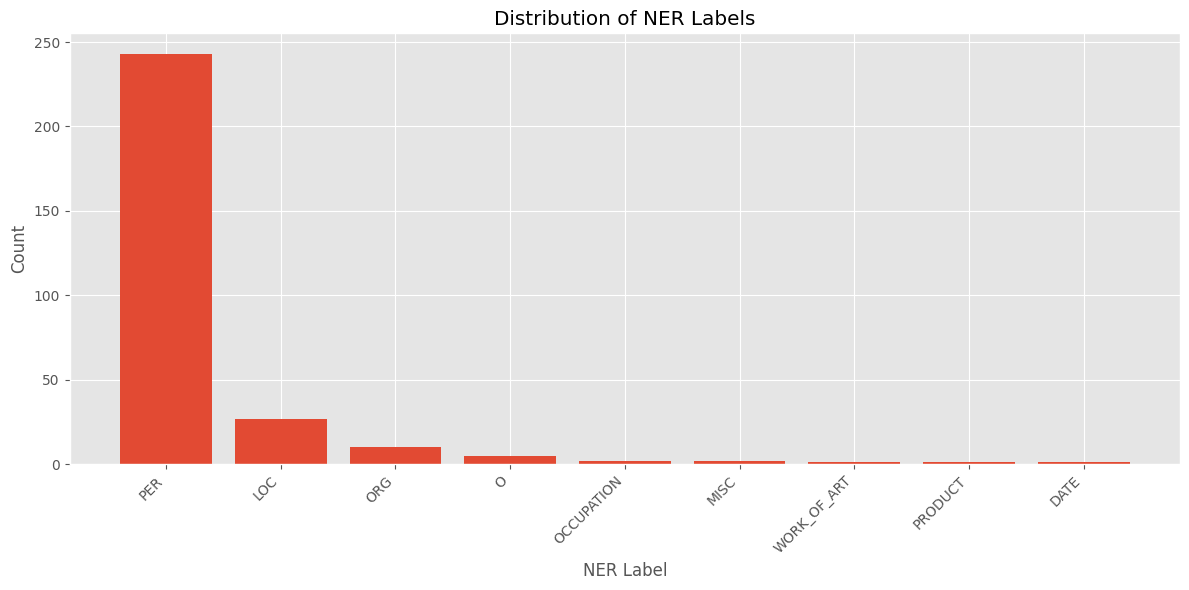

In [ ]:
import matplotlib.pyplot as plt
plt.style.use('ggplot') #

# Create a bar plot
plt.figure(figsize=(12, 6))
plt.bar(label_counts.index, label_counts.values)#, color='skyblue')

# Add title and labels
plt.title("Distribution of NER Labels")
plt.xlabel('NER Label')
plt.ylabel('Count')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Adjust layout
plt.tight_layout()

# Display the plot
plt.savefig('NER_espontaneo')
plt.show()

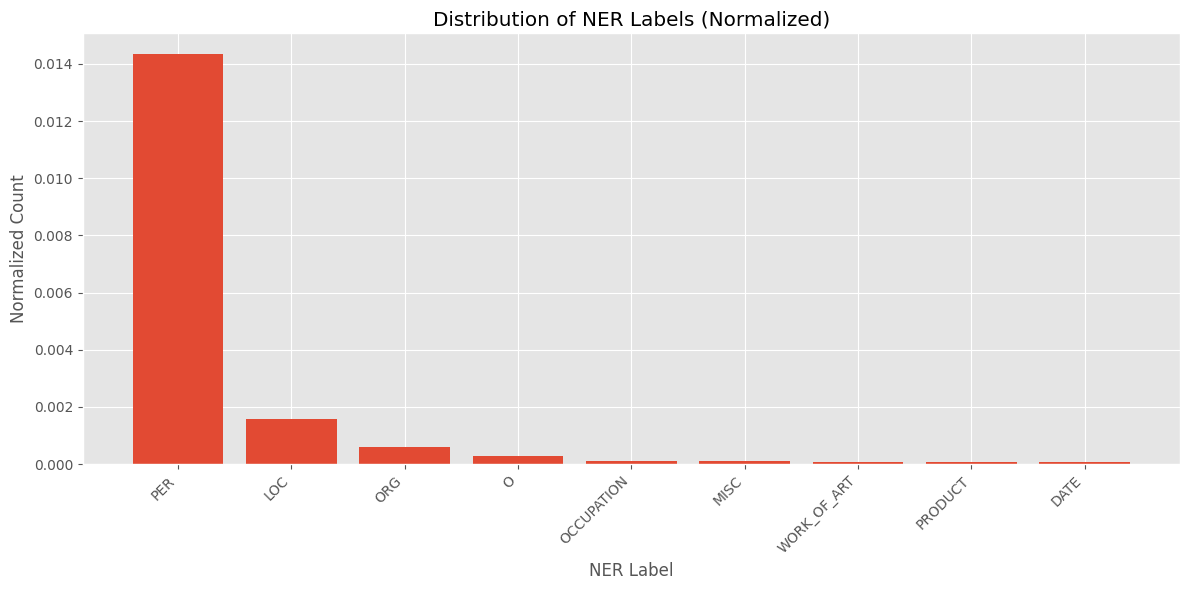

In [ ]:
# Create a bar plot with normalized values
normalization_factor = 16931
normalized_counts = label_counts.values / normalization_factor

plt.figure(figsize=(12, 6))
plt.bar(label_counts.index, normalized_counts)#, color='skyblue')

# Add title and labels
plt.title("Distribution of NER Labels (Normalized)")
plt.xlabel('NER Label')
plt.ylabel('Normalized Count')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Adjust layout
plt.tight_layout()

# Display the plot
plt.savefig('NER_espontaneo_normalized')
plt.show()

## Analyze Top Terms per Label



In [ ]:
processed_ner['term'] = processed_ner['term'].str.lower()
print("Updated processed_ner DataFrame with lowercase terms:")
print(processed_ner.head())
N = 45 # Number of top terms to display

print(f"Top {N} most frequent terms per NER label:")
print("\n" + "="*50 + "\n")

output_file_path = "NER_top_terms(espontaneo).txt"
with open(output_file_path, "w") as f:
    f.write(f"Top {N} most frequent terms per NER label:\n")
    f.write("\n" + "="*50 + "\n\n")

    for label in processed_ner['ner'].unique():
        # Filter DataFrame for the current label
        terms_for_label = processed_ner[processed_ner['ner'] == label]['term']

        # Calculate value counts and get the top N terms
        top_terms = terms_for_label.value_counts().head(N)

        if not top_terms.empty:
            print(f"Label: {label}")
            print(top_terms.to_string())
            print("\n" + "-"*50 + "\n")
            f.write(f"Label: {label}\n")
            f.write(top_terms.to_string())
            f.write("\n" + "-"*50 + "\n\n")
        else:
            print(f"Label: {label} - No terms found or less than {N} unique terms.")
            print("\n" + "-"*50 + "\n")
            f.write(f"Label: {label} - No terms found or less than {N} unique terms.\n")
            f.write("\n" + "-"*50 + "\n\n")

Updated processed_ner DataFrame with lowercase terms:
              term  ner
0        argentina  LOC
1        argentina  LOC
2          rodolfo  PER
3        argentina  LOC
4  santa argentina  LOC
Top 45 most frequent terms per NER label:


Label: LOC
term
argentina          13
izazaga             6
américa             2
eje central         1
santa argentina     1
condesa             1
méxico              1
estados unidos      1
ruta 7              1

--------------------------------------------------

Label: PER
term
benito                 42
carmelita              25
sor juana              23
gladys                 21
taxista                20
ricardito              17
josé                   15
dr. house              12
rodolfo                11
rompe piernas           9
novio                   8
fernandito              8
nemo                    7
manicurista             5
carmín                  3
amigo                   2
masajista               2
rudolfo                 1
gordo  

# Synthetic

In [ ]:
extracted_data = NER_results_syn['analysis'].apply(extract_text_and_label)

# Assign the results to new columns
NER_results_syn['extracted_texts'] = [x[0] for x in extracted_data]
NER_results_syn['extracted_labels'] = [x[1] for x in extracted_data]

# Display the head of the DataFrame with the new columns
#print(NER_results[['sentence', 'analysis', 'extracted_texts', 'extracted_labels']].head())

In [ ]:
NER_results_syn

,sentence,analysis,extracted_texts,extracted_labels
0,"Rodolfo: ¡Ay, Gladys, me siento como un reno e...","[\n {\n ""text"": ""Rodolfo"",\n ""label"": ""...","[Rodolfo, Gladys, Santa Claus, Grinch]","[PER, PER, PER, PER]"
1,José: ¡Ho ho ho! ¡Mira nada más quién viene po...,"[\n {""text"": ""José"", ""label"": ""PER""},\n {""te...","[José, Gladys, Rodolfo, Santa Claus, Polo Norte]","[PER, PER, PER, PER, LOC]"
2,"Gladys: ¡Ay, José, qué sorpresa verte aquí! Es...","[\n {""text"": ""Gladys"", ""label"": ""PER""},\n {""...","[Gladys, José, Navidad, Rodolfo, José, Rodolfo...","[PER, PER, MISC, PER, PER, PER, PER]"
3,"José: ¡Claro que no, Gladys! Aquí todos somos ...","[\n {""text"": ""José"", ""label"": ""PER""},\n {""te...","[José, Gladys, Jesús, Navidad, Polo Sur, Rodolfo]","[PER, PER, PER, MISC, LOC, PER]"
4,"Rodolfo: ¡Ay, José, no te creas que por ser el...","[\n {""text"": ""Rodolfo"", ""label"": ""PER""},\n {...","[Rodolfo, José, Santa, Gladys, Gladys, Navidad]","[PER, PER, PER, PER, PER, MISC]"
...,...,...,...,...
76,"Benito: ¡Max, eso suena como un plan perfecto!...","[\n {\n ""text"": ""Benito"",\n ""label"": ""P...","[Benito, Max, América, Benito en América]","[PER, PER, LOC, MISC]"
77,"Ricardito: ¡Ay, Benito! Pues yo digo que si lo...","[\n {\n ""text"": ""Ricardito"",\n ""label"":...","[Ricardito, Benito, Benito en América]","[PER, PER, WORK_OF_ART]"
78,"Benito: ¡Ay, Ricardito! Pues yo digo que con ""...","[\n {\n ""text"": ""Benito"",\n ""label"": ""P...","[Benito, Ricardito, Benito en América, América]","[PER, PER, WORK_OF_ART, LOC]"
79,"Ricardito: ¡Ay, claro que sí, Benito! ¡Con ""un...","[\n {\n ""text"": ""Ricardito"",\n ""label"":...","[Ricardito, Benito, Benito en América, América]","[PER, PER, WORK_OF_ART, LOC]"


In [ ]:
words_syn = NER_results_syn['extracted_texts'].tolist()
labels_syn = NER_results_syn['extracted_labels'].tolist()

# Flatten the words list
flat_words = []
for sublist in words_syn:
    flat_words.extend(sublist)
words = flat_words

flat_labels = []
for sublist in labels_syn:
    flat_labels.extend(sublist)
labels = flat_labels

if len(words) != len(labels):
    print("Error: The lists have different lengths.")

# Define a mapping for whole-word replacements
label_replacements = {
    "TECHNOLOGY": "TECH",
    "LOCATION": "LOC",
    "EVENTO": "EVENT",
    "TECNOLOGÍA": "TECH",
    "LUGAR": "LOC",
    "PRODUCTO": "PRODUCT",
    "PERSON": "PER",
    "PROD": "PRODUCT",
    "ORGANIZATION": "ORG",
    "Cantidad": "QUANTITY",
    "ORGANIZACIÓN": "ORG",
    "Tecnología": "TECH",
    "LEGISLACIÓN": "LAW",
    "FECHA": "DATE",
    "TECNOLOGIA": "TECH",
    "CANTIDAD_DE_DINERO": "MONEY",
    "CONCEPTO": "CONCEPT",
    "PORCENTAJE": "PERCENT",
    "OTRO": "OTHER",
    "Lugar": "LOC",
    "NUMBER": "NUM",
    "PRODUCTUCT": "PRODUCT", # Correcting a typo based on previous output
    "EVENTO_DEPORTIVO": "EVENT"
}

# Apply replacements only for whole word matches
normalized_labels = [label_replacements.get(label, label) for label in flat_labels]

# You can now use 'normalized_labels' for further analysis
print("Original flat_labels :", len(labels))
print("Normalized labels :", len(normalized_labels))

processed_ner = pd.DataFrame({'term': words, 'ner': normalized_labels})
label_counts = processed_ner['ner'].value_counts()
# Filter label_counts to show only items with counts greater than 5
#filtered_label_counts = label_counts[label_counts > 5]
print("Counts of each NER label (greater than 5):")
print(label_counts)

Original flat_labels : 178
Normalized labels : 178
Counts of each NER label (greater than 5):
ner
PER            148
LOC             13
MISC            11
WORK_OF_ART      3
DATE             1
ORG              1
PROFESION        1
Name: count, dtype: int64


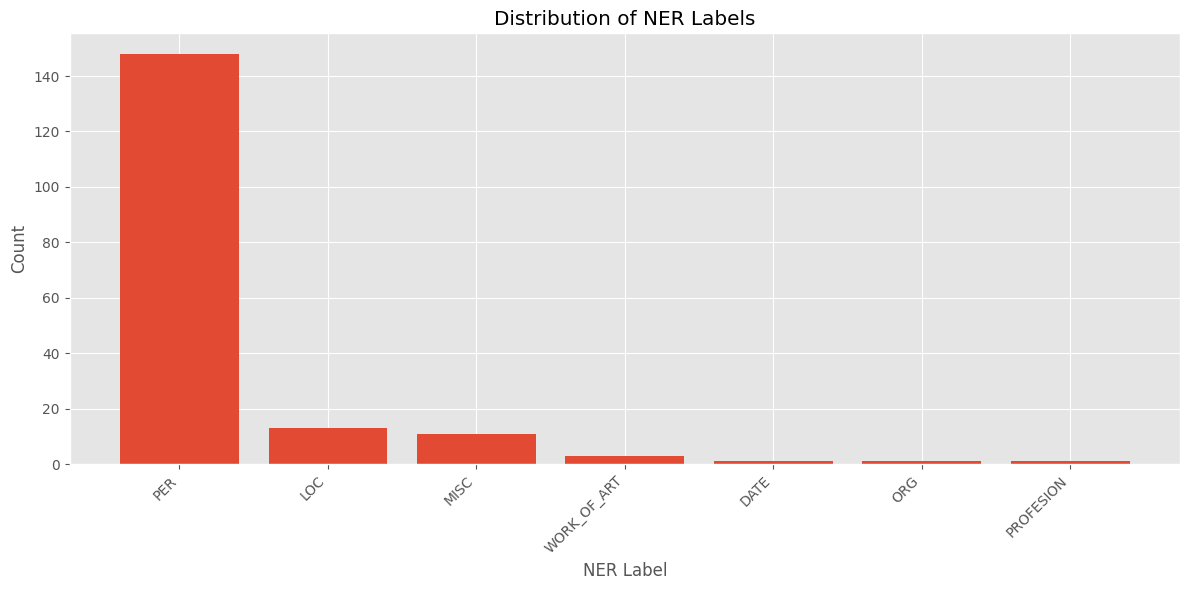

In [ ]:
import matplotlib.pyplot as plt
plt.style.use('ggplot') #

# Create a bar plot
plt.figure(figsize=(12, 6))
plt.bar(label_counts.index, label_counts.values)#, color='skyblue')

# Add title and labels
plt.title("Distribution of NER Labels")
plt.xlabel('NER Label')
plt.ylabel('Count')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Adjust layout
plt.tight_layout()

# Display the plot
plt.savefig('NER_sintetico')
plt.show()

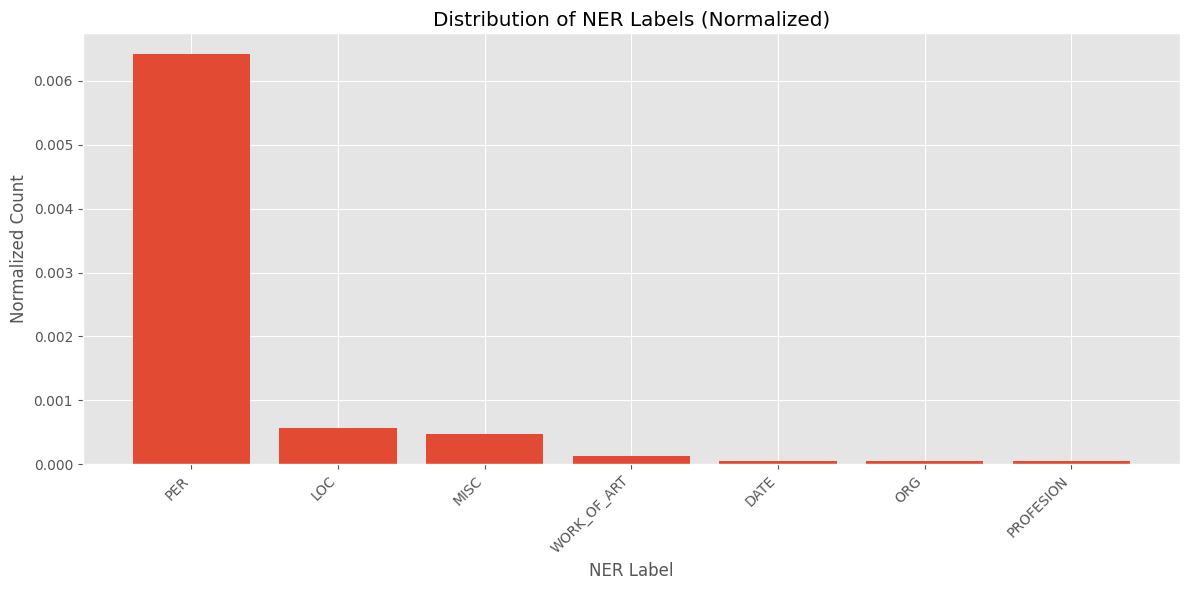

In [ ]:
# Create a bar plot with normalized values
normalization_factor = 23037
normalized_counts = label_counts.values / normalization_factor

plt.figure(figsize=(12, 6))
plt.bar(label_counts.index, normalized_counts)#, color='skyblue')

# Add title and labels
plt.title("Distribution of NER Labels (Normalized)")
plt.xlabel('NER Label')
plt.ylabel('Normalized Count')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Adjust layout
plt.tight_layout()

# Display the plot
plt.savefig('NER_sintetico_normalized')
plt.show()

In [ ]:
processed_ner['term'] = processed_ner['term'].str.lower()
print("Updated processed_ner DataFrame with lowercase terms:")
print(processed_ner.head())
N = 45 # Number of top terms to display

print(f"Top {N} most frequent terms per NER label:")
print("\n" + "="*50 + "\n")

output_file_path = "NER_top_terms(sintetico).txt"
with open(output_file_path, "w") as f:
    f.write(f"Top {N} most frequent terms per NER label:\n")
    f.write("\n" + "="*50 + "\n\n")

    for label in processed_ner['ner'].unique():
        # Filter DataFrame for the current label
        terms_for_label = processed_ner[processed_ner['ner'] == label]['term']

        # Calculate value counts and get the top N terms
        top_terms = terms_for_label.value_counts().head(N)

        if not top_terms.empty:
            print(f"Label: {label}")
            print(top_terms.to_string())
            print("\n" + "-"*50 + "\n")
            f.write(f"Label: {label}\n")
            f.write(top_terms.to_string())
            f.write("\n" + "-"*50 + "\n\n")
        else:
            print(f"Label: {label} - No terms found or less than {N} unique terms.")
            print("\n" + "-"*50 + "\n")
            f.write(f"Label: {label} - No terms found or less than {N} unique terms.\n")
            f.write("\n" + "-"*50 + "\n\n")

Updated processed_ner DataFrame with lowercase terms:
          term  ner
0      rodolfo  PER
1       gladys  PER
2  santa claus  PER
3       grinch  PER
4         josé  PER
Top 45 most frequent terms per NER label:


Label: PER
term
rodolfo                      23
gladys                       20
josé                         18
nemo                         11
dr. house                    11
benito                       10
sor juana inés de la cruz     7
ricardito                     7
max                           6
dory                          5
novio                         5
santa claus                   4
taxista                       4
juana                         2
grinch                        2
masajista                     2
doña juana                    2
jesús                         1
claus                         1
rudolf                        1
santa                         1
señor                         1
sor juana inés                1
teseo                         

Total tokens in espontaneo_lines: 16931

23037 sintético

155178 (all)